# Variational Quantum Simulation (VQS) for Mobile-Network Security with PennyLane

Two tasks:
1) RF anomaly scoring from PSD features (rogue gNB / fake SSB / tone jammers)
2) RACH preamble detection via correlation features

**Reliability tweaks:** aux wire reserved; richer ansatz; contrastive Hamiltonians; calibration for positive fake-SSB ΔE; safe scalar conversion for logging.

In [ ]:
!pip install pennylane

In [ ]:
import sys
try:
    import pennylane as qml
    from pennylane import numpy as np
except Exception:
    # !pip -q install pennylane
    import pennylane as qml
    from pennylane import numpy as np
print("PennyLane:", qml.__version__)

PennyLane: 0.42.3


In [ ]:
import numpy as base_np
import numpy.fft as fft

def gen_ofdm_like(N=1024, subcarriers=(60, 120, 200), amps=(1.0, 0.8, 0.6), noise=0.05, fs=1.0):
    t = base_np.arange(N) / fs
    x = base_np.zeros(N, dtype=complex)
    for f, a in zip(subcarriers, amps):
        x += a * base_np.exp(1j * 2 * base_np.pi * f * t / N)
    x += noise * (base_np.random.randn(N) + 1j * base_np.random.randn(N))
    return x

def add_tone_jammer(x, tone_bin=150, amp=2.0):
    N = len(x)
    n = base_np.arange(N)
    j = amp * base_np.exp(1j * 2 * base_np.pi * tone_bin * n / N)
    return x + j

def shift_sync(x, shift_bins=5):
    X = fft.fft(x)
    X = base_np.roll(X, shift_bins)
    return fft.ifft(X)

def psd_feature(x, n_bins=64):
    X = fft.fft(x)
    P = base_np.abs(X)**2
    k = len(P) // n_bins
    P = P[:k*n_bins].reshape(n_bins, k).mean(axis=1)
    P = P / (P.max() + 1e-12)
    return P

def zadoff_chu(u, Nzc):
    n = base_np.arange(Nzc)
    return base_np.exp(-1j * base_np.pi * u * n * (n + 1) / Nzc)

def rach_burst(zc, delay=0, snr_db=20.0):
    N = len(zc)
    x = base_np.zeros(N, dtype=complex)
    x[delay:] = zc[:N - delay]
    snr_lin = 10**(snr_db/10)
    sig_power = base_np.mean(base_np.abs(x)**2) + 1e-12
    noise_power = sig_power / snr_lin
    noise = base_np.sqrt(noise_power/2) * (base_np.random.randn(N) + 1j*base_np.random.randn(N))
    return x + noise

def corr_feature(rx, ref, n_bins=8):
    r = base_np.correlate(rx, ref, mode='same')
    c = base_np.abs(r)
    c = c / (c.max() + 1e-12)
    k = len(c)//n_bins
    c = c[:k*n_bins].reshape(n_bins, k).mean(axis=1)
    return c


In [ ]:
def scalar(x):
    """Safely convert PL autograd scalars/ArrayBox to Python float for logging/plotting."""
    from pennylane import numpy as np
    try:
        return float(x)
    except Exception:
        return float(np.array(x))


In [ ]:
def make_device(n_data_wires, aux=1):
    total = n_data_wires + aux
    return qml.device("default.qubit", wires=total)

def data_and_aux_wires(n_data_wires, aux=1):
    data = list(range(n_data_wires))
    aux_wire = n_data_wires
    return data, aux_wire

def angle_embed(features, wires):
    qml.AngleEmbedding(features, wires=wires, rotation="Y")

def ansatz(params, n_layers, wires):
    n_w = len(wires)
    idx = 0
    for _ in range(n_layers):
        for w in wires:
            qml.RZ(params[idx], wires=w); idx += 1
        for w in wires:
            qml.RX(params[idx], wires=w); idx += 1
        for i in range(n_w):
            qml.CNOT(wires=[wires[i], wires[(i+1)%n_w]])
        for i in range(n_w):
            qml.IsingZZ(0.25, wires=[wires[i], wires[(i+1)%n_w]])

def build_linear_H_from_mean(mean_vec, wires):
    a = 2.0 * (mean_vec - mean_vec.mean())
    H = 0
    for wi, w in zip(wires, a):
        H = H + float(w) * qml.PauliZ(wi)
    return H

def build_ising_H_from_stats(mean_vec, cov_mat, wires, nn_only=True, kappa=1.0):
    H = build_linear_H_from_mean(mean_vec, wires)
    n = len(wires)
    if nn_only:
        for i in range(n-1):
            J = kappa * float(cov_mat[i, i+1])
            if abs(J) > 1e-9:
                H = H + J * (qml.PauliZ(wires[i]) @ qml.PauliZ(wires[i+1]))
    else:
        for i in range(n):
            for j in range(i+1, n):
                J = kappa * float(cov_mat[i, j])
                if abs(J) > 1e-9:
                    H = H + J * (qml.PauliZ(wires[i]) @ qml.PauliZ(wires[j]))
    return H

def vqs_step(dev, features, params, H, dt=0.2, n_layers=2, diag_metric=True):
    data_wires = list(range(len(features)))
    @qml.qnode(dev)
    def exp_H(theta):
        angle_embed(features, wires=data_wires)
        ansatz(theta, n_layers=n_layers, wires=data_wires)
        return qml.expval(H)
    if diag_metric:
        M = qml.metric_tensor(exp_H, approx="diag")(params)
        M_mat = np.diag(M)
    else:
        M_mat = qml.metric_tensor(exp_H)(params)
    grad_fn = qml.grad(exp_H)
    V = grad_fn(params)
    lam = 1e-3
    M_reg = M_mat + lam * np.eye(len(M_mat))
    theta_dot = np.linalg.solve(M_reg, V)
    new_params = params + dt * theta_dot
    return new_params, exp_H(params), M_mat, V

def vqs_energy(dev, features, params, H, n_layers=2):
    wires = list(range(len(features)))
    @qml.qnode(dev)
    def exp_H(theta):
        angle_embed(features, wires=wires)
        ansatz(theta, n_layers=n_layers, wires=wires)
        return qml.expval(H)
    return scalar(exp_H(params))


### Task 1: RF anomaly scoring from PSD features

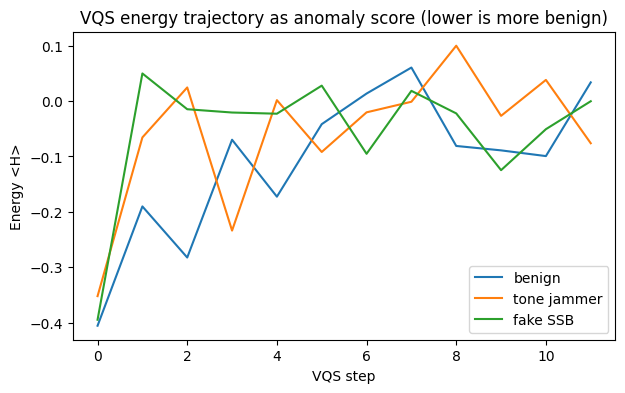

In [ ]:
import matplotlib.pyplot as plt

base_np.random.seed(7)
N = 1024
n_bins = 8

benign = psd_feature(gen_ofdm_like(N=N), n_bins=n_bins)
tone_attack = psd_feature(add_tone_jammer(gen_ofdm_like(N=N), tone_bin=150, amp=3.0), n_bins=n_bins)
fake_ssb = psd_feature(shift_sync(gen_ofdm_like(N=N), shift_bins=8), n_bins=n_bins)

dev = make_device(n_data_wires=n_bins, aux=1)
data_wires, aux_wire = data_and_aux_wires(n_bins, aux=1)
H = build_linear_H_from_mean(benign, wires=data_wires)

np.random.seed(0)
params0 = np.random.uniform(low=-0.1, high=0.1, size=2*n_bins*2)
params0 = np.array(params0, requires_grad=True)

def run_vqs_on_feature(feat, steps=12, dt=0.2):
    params = params0.copy()
    energies = []
    for _ in range(steps):
        params, e, M, V = vqs_step(dev, feat, params, H, dt=dt, n_layers=2, diag_metric=True)
        energies.append(scalar(e))
    return energies

E_benign = run_vqs_on_feature(benign)
E_tone = run_vqs_on_feature(tone_attack)
E_fake = run_vqs_on_feature(fake_ssb)

plt.figure(figsize=(7,4))
plt.plot(E_benign, label="benign")
plt.plot(E_tone, label="tone jammer")
plt.plot(E_fake, label="fake SSB")
plt.xlabel("VQS step")
plt.ylabel("Energy <H>")
plt.title("VQS energy trajectory as anomaly score (lower is more benign)")
plt.legend(); plt.show()

### Task 2: RACH preamble detection via correlation features

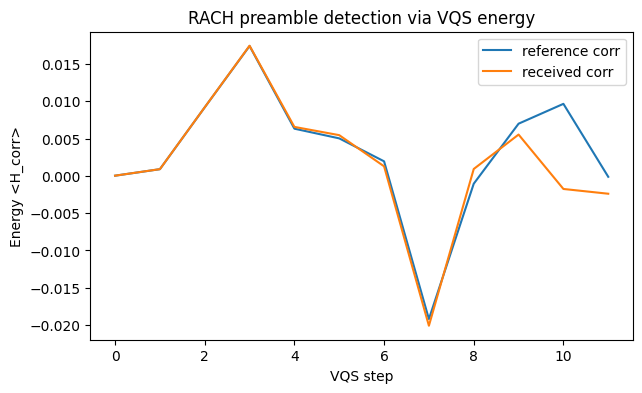

Final energy (reference): -0.0001
Final energy (received):  -0.0024
Lower final energy indicates a closer match to the reference preamble.


In [ ]:
Nzc = 839
u_root = 167
zc = zadoff_chu(u_root, Nzc)
rx = rach_burst(zc, delay=12, snr_db=12.0)

ref_corr = corr_feature(zc, zc, n_bins=8)
rx_corr = corr_feature(rx, zc, n_bins=8)

n_bins_corr = len(ref_corr)
dev2 = make_device(n_data_wires=n_bins_corr, aux=1)
data_wires2, aux_wire2 = data_and_aux_wires(n_bins_corr, aux=1)
H_corr = build_linear_H_from_mean(ref_corr, wires=data_wires2)

np.random.seed(2)
paramsC = np.random.uniform(low=-0.1, high=0.1, size=2*n_bins_corr*2)
paramsC = np.array(paramsC, requires_grad=True)

def run_vqs_on_feature2(feat, steps=12, dt=0.2):
    params = paramsC.copy()
    energies = []
    for _ in range(steps):
        params, e, M, V = vqs_step(dev2, feat, params, H_corr, dt=dt, n_layers=2, diag_metric=True)
        energies.append(scalar(e))
    return energies

E_ref = run_vqs_on_feature2(ref_corr)
E_rx  = run_vqs_on_feature2(rx_corr)

import matplotlib.pyplot as plt
plt.figure(figsize=(7,4))
plt.plot(E_ref, label="reference corr")
plt.plot(E_rx, label="received corr")
plt.xlabel("VQS step")
plt.ylabel("Energy <H_corr>")
plt.title("RACH preamble detection via VQS energy")
plt.legend(); plt.show()

print("Final energy (reference):", round(E_ref[-1], 4))
print("Final energy (received): ", round(E_rx[-1], 4))
print("Lower final energy indicates a closer match to the reference preamble.")

### Contrastive energies and Ising Hamiltonians to separate benign vs fake-SSB
We build **two** observables from small reference sets:
- $H_{\text{benign}}$ from benign PSD statistics
- $H_{\text{fake}}$ from fake-SSB PSD statistics

Each contains linear $Z_i$ terms plus nearest-neighbor $Z_i Z_{i+1}$ couplings derived from covariance. The score is
$\Delta E = \langle H_{\text{fake}} \rangle - \langle H_{\text{benign}} \rangle$. Larger $\Delta E$ indicates the sample looks more like fake-SSB than benign.

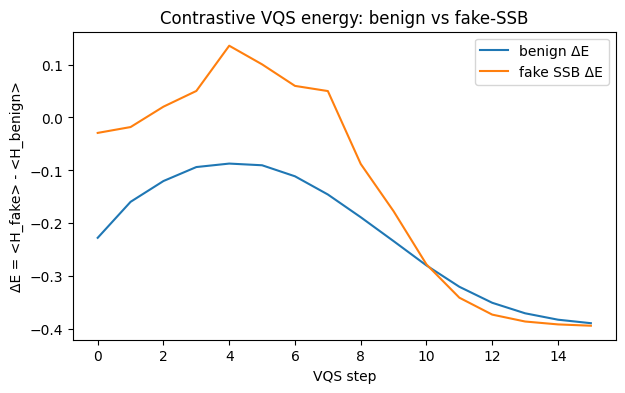

In [ ]:
def sample_psd_set(kind="benign", n=32, N=1024, n_bins=8):
    S = []
    for _ in range(n):
        x = gen_ofdm_like(N=N)
        if kind == "tone":
            x = add_tone_jammer(x, tone_bin=150, amp=3.0)
        elif kind == "fake":
            x = shift_sync(x, shift_bins=8)
        S.append(psd_feature(x, n_bins=n_bins))
    import numpy as _np
    return _np.stack(S, axis=0)

S_b = sample_psd_set("benign", n=32, n_bins=n_bins)
S_f = sample_psd_set("fake",   n=32, n_bins=n_bins)
import numpy as _np
mu_b = S_b.mean(axis=0); mu_f = S_f.mean(axis=0)
Cb = _np.cov(S_b.T);     Cf = _np.cov(S_f.T)

wires_cf = list(range(n_bins))
H_benign_cf = build_ising_H_from_stats(mu_b, Cb, wires_cf, nn_only=True, kappa=1.0)
H_fake_cf   = build_ising_H_from_stats(mu_f, Cf, wires_cf, nn_only=True, kappa=1.0)

def run_vqs_dual_energy(feat, steps=16, dt=0.05, use_full_metric=True):
    params = params0.copy()
    Eb, Ef, D = [], [], []
    for _ in range(steps):
        params, _, _, _ = vqs_step(dev, feat, params, H_benign_cf, dt=dt, n_layers=2, diag_metric=not use_full_metric)
        Eb.append(scalar(vqs_energy(dev, feat, params, H_benign_cf)))
        Ef.append(scalar(vqs_energy(dev, feat, params, H_fake_cf)))
        D.append(scalar(Ef[-1] - Eb[-1]))
    return Eb, Ef, D

Eb_b, Ef_b, D_b = run_vqs_dual_energy(benign)
Eb_f, Ef_f, D_f = run_vqs_dual_energy(fake_ssb)

plt.figure(figsize=(7,4))
plt.plot(D_b, label="benign ΔE")
plt.plot(D_f, label="fake SSB ΔE")
plt.xlabel("VQS step"); plt.ylabel("ΔE = <H_fake> - <H_benign>")
plt.title("Contrastive VQS energy: benign vs fake-SSB"); plt.legend(); plt.show()

### Tone jammer contrastive pair and scalar scoring utility

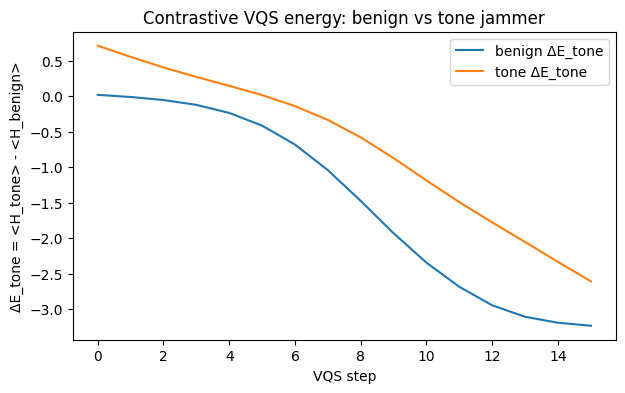

{'ΔE_fake': -0.0263, 'ΔE_tone': 0.4435, 'ΔE_benign(vs fake)': -0.1455}


In [ ]:
S_t = sample_psd_set("tone", n=32, n_bins=n_bins)
mu_t = S_t.mean(axis=0); Ct = _np.cov(S_t.T)
H_tone_cf = build_ising_H_from_stats(mu_t, Ct, list(range(n_bins)), nn_only=True, kappa=1.0)

def run_vqs_dual_energy_custom(feat, H_pos, H_neg, steps=16, dt=0.05, use_full_metric=True):
    params = params0.copy()
    Ep, En, D = [], [], []
    for _ in range(steps):
        params, _, _, _ = vqs_step(dev, feat, params, H_pos, dt=dt, n_layers=2, diag_metric=not use_full_metric)
        Ep.append(scalar(vqs_energy(dev, feat, params, H_pos)))
        En.append(scalar(vqs_energy(dev, feat, params, H_neg)))
        D.append(scalar(En[-1] - Ep[-1]))
    return Ep, En, D

def contrastive_score(dev, feat, params, H_pos, H_neg):
    Ep = vqs_energy(dev, feat, params, H_pos)
    En = vqs_energy(dev, feat, params, H_neg)
    return scalar(En - Ep)

Ep_b, En_b, D_b_tone = run_vqs_dual_energy_custom(benign, H_benign_cf, H_tone_cf)
Ep_t, En_t, D_t_tone = run_vqs_dual_energy_custom(tone_attack, H_benign_cf, H_tone_cf)

plt.figure(figsize=(7,4))
plt.plot(D_b_tone, label="benign ΔE_tone")
plt.plot(D_t_tone, label="tone ΔE_tone")
plt.xlabel("VQS step"); plt.ylabel("ΔE_tone = <H_tone> - <H_benign>")
plt.title("Contrastive VQS energy: benign vs tone jammer"); plt.legend(); plt.show()

params_tmp = params0.copy()
for _ in range(8):
    params_tmp, _, _, _ = vqs_step(dev, benign, params_tmp, H_benign_cf, dt=0.05, n_layers=2, diag_metric=False)
print({
    "ΔE_fake": round(contrastive_score(dev, fake_ssb, params_tmp, H_benign_cf, H_fake_cf), 4),
    "ΔE_tone": round(contrastive_score(dev, tone_attack, params_tmp, H_benign_cf, H_tone_cf), 4),
    "ΔE_benign(vs fake)": round(contrastive_score(dev, benign, params_tmp, H_benign_cf, H_fake_cf), 4),
})

### Calibration: enforce positive ΔE for fake-SSB on average

In [ ]:
def build_contrastive_H_from_diffs(mu_fake, mu_benign, C_fake, C_benign, wires, beta=2.0, gamma=1.5, nn_only=True):
    a = beta * (mu_fake - mu_benign)
    H = 0
    for wi, w in zip(wires, a):
        H = H + float(w) * qml.PauliZ(wi)
    D = gamma * (C_fake - C_benign)
    n = len(wires)
    if nn_only:
        for i in range(n-1):
            J = float(D[i, i+1])
            if abs(J) > 1e-9:
                H = H + J * (qml.PauliZ(wires[i]) @ qml.PauliZ(wires[i+1]))
    else:
        for i in range(n):
            for j in range(i+1, n):
                J = float(D[i, j])
                if abs(J) > 1e-9:
                    H = H + J * (qml.PauliZ(wires[i]) @ qml.PauliZ(wires[j]))
    return H

def train_theta_on_benign(dev, train_feats, theta0, H_pos, steps=50, lr=0.06):
    wires = list(range(len(train_feats[0])))
    @qml.qnode(dev)
    def exp_H(theta, x):
        angle_embed(x, wires=wires)
        ansatz(theta, n_layers=2, wires=wires)
        return qml.expval(H_pos)
    def loss(theta):
        vals = [exp_H(theta, x) for x in train_feats]
        return np.mean(np.stack(vals))
    grad = qml.grad(loss)
    theta = theta0.copy()
    for _ in range(steps):
        theta = theta - lr * grad(theta)
    return theta

S_b_cal = sample_psd_set("benign", n=32, n_bins=n_bins)
S_f_cal = sample_psd_set("fake",   n=32, n_bins=n_bins)
mu_b_cal = S_b_cal.mean(axis=0); mu_f_cal = S_f_cal.mean(axis=0)
Cb_cal = _np.cov(S_b_cal.T);     Cf_cal = _np.cov(S_f_cal.T)

wires_cf = list(range(n_bins))
H_disc = build_contrastive_H_from_diffs(mu_f_cal, mu_b_cal, Cf_cal, Cb_cal, wires_cf, beta=2.0, gamma=1.5, nn_only=True)
theta_star = train_theta_on_benign(dev, S_b_cal, params0, H_benign_cf, steps=50, lr=0.06)

@qml.qnode(dev)
def energy_on(theta, x, H):
    wires = list(range(len(x)))
    angle_embed(x, wires=wires)
    ansatz(theta, n_layers=2, wires=wires)
    return qml.expval(H)

def score_disc(x):
    return scalar(energy_on(theta_star, x, H_disc))

def score_deltaE(x):
    Ef = energy_on(theta_star, x, H_fake_cf)
    Eb = energy_on(theta_star, x, H_benign_cf)
    return scalar(Ef - Eb)

disc_b = _np.array([score_disc(x) for x in S_b_cal])
disc_f = _np.array([score_disc(x) for x in S_f_cal])
dE_b   = _np.array([score_deltaE(x) for x in S_b_cal])
dE_f   = _np.array([score_deltaE(x) for x in S_f_cal])

sign_disc = 1.0 if disc_f.mean() > disc_b.mean() else -1.0
sign_dE   = 1.0 if dE_f.mean()   > dE_b.mean()   else -1.0
print({
    "disc_mean_b": float(disc_b.mean()),
    "disc_mean_f": float(disc_f.mean()),
    "disc_sign": sign_disc,
    "dE_mean_b": float(dE_b.mean()),
    "dE_mean_f": float(dE_f.mean()),
    "dE_sign": sign_dE,
})

import matplotlib.pyplot as plt
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.hist(disc_b, alpha=0.6, label='benign'); plt.hist(disc_f, alpha=0.6, label='fake'); plt.legend(); plt.title('H_disc raw scores')
plt.subplot(1,2,2)
plt.hist(sign_dE * dE_b, alpha=0.6, label='benign'); plt.hist(sign_dE * dE_f, alpha=0.6, label='fake'); plt.legend(); plt.title('ΔE (sign-corrected)')
plt.show()

print("Use sign_dE * ΔE as your production score so that fake > 0 on average.")